# 感度分析

担当：岩間

`optimize()` を条件を変えて繰り返し呼び、次の4つを作る。

1. 節約額（外食のみとの差を1日・1週間・1か月で）
2. 損益分岐（準備時間の上限を動かしたときの最小コストと、構成が入れ替わる上限）
3. ロス率 × 準備時間のヒートマップ用の表
4. 上の3つを描く可視化関数（Plotly の figure を返す）

関数の定義セルは `st.` と `config` を使わない（引数と戻り値だけで渡す）。第7回で `.py` に書き出して `app.py` から呼ぶ。

In [1]:
# ファイルの読み込み（optimize.ipynb の関数定義セルを読むために使う）
import json
# 数値計算（配列での一括計算）
import numpy as np
# 表データの読み込みと加工
import pandas as pd
# グラフ描画（Plotly）
import plotly.graph_objects as go

# 共通の仮定値（config.py）
import config

## optimize.ipynb の関数を読み込む

ノートブックどうしは `import` できないため、`optimize.ipynb` の関数定義セルだけを実行して `assign_slots` と `optimize` を取り出す。
第7回に `.py` へ移したら、このセルは `from optimize import assign_slots, optimize` に置き換える。

In [2]:
def load_optimize_defs(path="optimize.ipynb"):
    """optimize.ipynb のうち、関数を定義しているセルだけを実行して、名前空間(dict)を返す。"""
    # ノートブック（JSON）を読む
    with open(path, encoding="utf-8") as f:
        nb = json.load(f)
    # 関数定義セルの中で使う名前（np, pd）を先に渡しておく
    ns = {"np": np, "pd": pd}
    # セルを1つずつ見る
    for cell in nb["cells"]:
        # セルの中身を1つの文字列にする
        src = "".join(cell["source"])
        # 動作確認セルは実行しない（定義セルだけ）。assign_slots のセルと optimize のセルが対象
        if cell["cell_type"] == "code" and ("def assign_slots" in src or "def _update_best" in src):
            # 定義を ns の中で実行する（関数や SLOTS, EPS が ns に入る）
            exec(src, ns)
    return ns


# optimize.ipynb の定義を読み込む
_ns = load_optimize_defs()
# 枠の名前（朝・昼・夜）
SLOTS = _ns["SLOTS"]
# 境界値を落とさないための微小値
EPS = _ns["EPS"]
# 枠ごとの候補フラグ（can_*）を付ける関数
assign_slots = _ns["assign_slots"]
# 1日分の最適化関数
optimize = _ns["optimize"]

## 関数の定義（節約額）

`meals.csv` の `type` 列は「外食」「自炊」。自炊の `cost_yen` は `base_cost_yen ÷ (1 − ロス率)` で、外食は `base_cost_yen` のまま。

In [3]:
EATOUT = "外食"  # meals.csv の type 列の値
COOK = "自炊"    # 同上


def apply_loss(meals_df, loss_rate):
    """自炊メニューの cost_yen を base_cost_yen ÷ (1 − loss_rate) で再計算して返す。外食は変えない。

    入力: meals_df（type, base_cost_yen, cost_yen 列が必要）、loss_rate（0以上1未満。例 0.1 = 10%）
    戻り値: 新しい DataFrame（元の表は書き換えない）
    """
    # ロス率が範囲外（負、または1以上）なら止める。1以上だと 1−ロス率 が0以下で計算できない
    if not 0 <= loss_rate < 1:
        raise ValueError(f"loss_rate は0以上1未満にする: {loss_rate}")
    out = meals_df.copy()  # 元の表は書き換えない
    out["cost_yen"] = out["cost_yen"].astype(float)  # 小数を入れるので float にしておく
    cooked = out["type"] == COOK  # 自炊の行（True/False の列）
    # 食材費 ÷ (1 − ロス率) ＝ 捨てる分も含めて買う量が増える分の費用
    out.loc[cooked, "cost_yen"] = out.loc[cooked, "base_cost_yen"] / (1 - loss_rate)
    return out


def eatout_baseline(meals_slot, budget_yen, nutrition_target, aux_nutrients=()):
    """外食だけで組んだときの最小コスト（準備時間は制約なし）。optimize と同じ dict を返す。

    準備時間を制約にしないのは、損益分岐の「外食のみの水平線」を上限によらず一定にするため。
    """
    # 外食の行だけに絞る（can_* 列は残ったまま）
    eat = meals_slot[meals_slot["type"] == EATOUT]
    # 準備時間の上限を無限大にして、予算と栄養だけの制約で最適化する
    return optimize(eat, budget_yen, np.inf, nutrition_target, aux_nutrients)


def savings(best, baseline, days_week=7, days_month=30):
    """最適な1日と外食のみの1日の差を、1日・1週間・1か月の節約額にする。

    入力: best（optimize の戻り値）、baseline（eatout_baseline の戻り値）
    戻り値（dict）: feasible, eatout_cost, best_cost, per_day, per_week, per_month（円）
      どちらかが解なしなら feasible=False で他は None。
      マイナスは「準備時間の上限のせいで外食のみより高くなる」を意味する。
    """
    # どちらかが解なしなら、差は計算できないので None を返す
    if not (best["feasible"] and baseline["feasible"]):
        return {"feasible": False, "eatout_cost": None, "best_cost": None,
                "per_day": None, "per_week": None, "per_month": None}
    per_day = baseline["total_cost"] - best["total_cost"]  # 1日あたりの節約額（外食のみ − 最適）
    return {"feasible": True,
            "eatout_cost": baseline["total_cost"], "best_cost": best["total_cost"],
            # 1週間・1か月は、1日の節約額に日数をかけただけ（毎日同じ条件で食べる前提）
            "per_day": per_day, "per_week": per_day * days_week, "per_month": per_day * days_month}

## 関数の定義（損益分岐・ヒートマップ用の表）

In [4]:
def breakeven_curve(meals_slot, budget_yen, prep_grid, nutrition_target):
    """準備時間の上限を prep_grid の値に動かして optimize を繰り返し、1日の最小コストを返す。

    戻り値（DataFrame、prep_grid の1値につき1行）
      max_prep_min: 準備時間の上限（分）
      feasible: 解があるか
      total_cost: 1日の最小コスト（円）。解なしは NaN
      prep_used: 実際に使う準備時間の合計（分）。解なしは NaN
      n_cooked: 選ばれた3食のうち自炊の食数。解なしは NaN
      meal_ids: 選ばれた3食の meal_id（朝・昼・夜の順の tuple）。解なしは None
      eatout_cost: 外食のみの最小コスト（円・全行同じ値）。外食だけでは解なしなら NaN
    """
    # 外食のみの最小コスト（水平線用）。上限によらないので1回だけ求める
    base = eatout_baseline(meals_slot, budget_yen, nutrition_target)
    base_cost = base["total_cost"] if base["feasible"] else np.nan  # 解なしは NaN
    rows = []  # 上限ごとの結果を1行ずつ貯める
    for prep in prep_grid:
        # この上限での最適な1日
        r = optimize(meals_slot, budget_yen, prep, nutrition_target)
        if r["feasible"]:
            sel = r["selected"]  # 選ばれた3食の表
            rows.append({"max_prep_min": prep, "feasible": True, "total_cost": r["total_cost"],
                         "prep_used": float(sel["prep_min"].sum()),    # 準備時間の合計
                         "n_cooked": int((sel["type"] == COOK).sum()),  # 自炊の食数
                         "meal_ids": tuple(sel["meal_id"])})            # 朝・昼・夜の順の meal_id
        else:
            # 解なしの行は、数値を NaN にして残す（グラフでは線が途切れる）
            rows.append({"max_prep_min": prep, "feasible": False, "total_cost": np.nan,
                         "prep_used": np.nan, "n_cooked": np.nan, "meal_ids": None})
    out = pd.DataFrame(rows)
    out["eatout_cost"] = base_cost  # 全行に同じ値（外食のみ）を入れる
    return out


def switch_points(curve):
    """breakeven_curve の結果から、損益分岐に当たる上限値を取り出す。

    戻り値（dict）。値は prep_grid の刻みの値（その上限「以上」で起きる、の意味）。
      first_feasible_prep: 解が初めて出る上限（分）。なければ None
      crossover_prep: 外食のみより安くなり始める上限（分）。安くならなければ None
      switch_preps: 選ばれる3食の組み合わせが前の上限から変わる上限（分）のリスト
    """
    out = {"first_feasible_prep": None, "crossover_prep": None, "switch_preps": []}
    ok = curve[curve["feasible"]].reset_index(drop=True)  # 解のある行だけ
    # 解のある行が1つもなければ、全部 None のまま返す
    if ok.empty:
        return out
    out["first_feasible_prep"] = int(ok.loc[0, "max_prep_min"])  # 最初に解が出る上限
    base = ok.loc[0, "eatout_cost"]  # 外食のみのコスト（NaN の場合あり）
    if pd.notna(base):
        # 外食のみより安い行（EPS は小数の誤差で同額を「安い」としないための余裕）
        cheaper = ok[ok["total_cost"] < base - EPS]
        if not cheaper.empty:
            out["crossover_prep"] = int(cheaper["max_prep_min"].iloc[0])  # 最初にそうなる上限
    prev = None  # 前の上限で選ばれた組み合わせ（朝昼夜の順は無視して比べる）
    for _, row in ok.iterrows():
        key = tuple(sorted(row["meal_ids"]))  # 並べ替えて、枠の入れ替えだけなら同じ扱いにする
        # 前の行と組み合わせが違えば、その上限を記録する
        if prev is not None and key != prev:
            out["switch_preps"].append(int(row["max_prep_min"]))
        prev = key
    return out


def loss_prep_grid(meals_slot, budget_yen, prep_grid, loss_grid, nutrition_target):
    """ロス率 × 準備時間の上限の全組み合わせで optimize を回し、縦持ちの表を返す。

    戻り値（DataFrame、組み合わせ1つにつき1行）
      loss_rate, max_prep_min, feasible, total_cost（解なしは NaN）,
      saving_per_day（外食のみとの差・円/日。外食のみが解なしなら NaN）, n_cooked（解なしは NaN）
    """
    base = eatout_baseline(meals_slot, budget_yen, nutrition_target)  # 外食はロス率に関係しないので1回だけ
    base_cost = base["total_cost"] if base["feasible"] else np.nan    # 解なしは NaN
    rows = []  # 組み合わせごとの結果を1行ずつ貯める
    for loss in loss_grid:
        m = apply_loss(meals_slot, loss)  # このロス率での自炊コストに直した表
        for prep in prep_grid:
            # このロス率・この上限での最適な1日
            r = optimize(m, budget_yen, prep, nutrition_target)
            if r["feasible"]:
                rows.append({"loss_rate": loss, "max_prep_min": prep, "feasible": True,
                             "total_cost": r["total_cost"],
                             "saving_per_day": base_cost - r["total_cost"],  # 外食のみとの差
                             "n_cooked": int((r["selected"]["type"] == COOK).sum())})
            else:
                # 解なしは NaN で残す（ヒートマップでは灰色のセルになる）
                rows.append({"loss_rate": loss, "max_prep_min": prep, "feasible": False,
                             "total_cost": np.nan, "saving_per_day": np.nan, "n_cooked": np.nan})
    return pd.DataFrame(rows)

## 関数の定義（栄養制約の差・調理時間の感度分析）

- `nutrition_cost_gap`: 栄養制約あり／なしの最小コストの差（栄養を満たすために余分にかかる額）
- `apply_cook_time`: 自炊の準備時間（`prep_min`）を倍率で変える（調理時間の感度分析用）
- `oat_sensitivity`: **OAT（one-at-a-time）**。基準の条件から、準備時間の上限・ロス率・調理時間の倍率を**1つずつ**動かし、他は基準のままにして最小コストの変化を見る

In [5]:
def nutrition_cost_gap(meals_slot, budget_yen, max_prep_min, nutrition_target):
    """栄養制約あり／なしの最小コストの差を返す（栄養を満たすために、いくら余分にかかるか）。

    「栄養制約なし」は nutrition_target を空にして最適化する。
    予算・準備時間・朝昼夜の枠の条件（kcal による枠の絞り込み）は、あり／なしで同じ。
    戻り値（dict）
      with_nutrition / without_nutrition: optimize の戻り値（栄養制約あり／なし）
      cost_with / cost_without: それぞれの最小コスト（円）。解なしは None
      gap_yen: cost_with − cost_without（円）。0以上になる。どちらかが解なしなら None
    """
    # 栄養制約あり
    with_n = optimize(meals_slot, budget_yen, max_prep_min, nutrition_target)
    # 栄養制約なし（空の辞書にすると、栄養の条件が全部なくなる）
    without_n = optimize(meals_slot, budget_yen, max_prep_min, {})
    cost_with = with_n["total_cost"] if with_n["feasible"] else None
    cost_without = without_n["total_cost"] if without_n["feasible"] else None
    # どちらかが解なしなら、差は計算できない
    gap = None if cost_with is None or cost_without is None else cost_with - cost_without
    return {"with_nutrition": with_n, "without_nutrition": without_n,
            "cost_with": cost_with, "cost_without": cost_without, "gap_yen": gap}


def apply_cook_time(meals_df, factor):
    """自炊メニューの prep_min（調理＋片付け）を factor 倍にして返す。外食は変えない。

    入力: meals_df（type, prep_min 列が必要）、factor（0より大きい。例 1.2 = 20%長くかかる）
    戻り値: 新しい DataFrame（元の表は書き換えない）
    """
    # 0以下の倍率は意味がないので止める
    if factor <= 0:
        raise ValueError(f"factor は0より大きくする: {factor}")
    out = meals_df.copy()  # 元の表は書き換えない
    out["prep_min"] = out["prep_min"].astype(float)  # 倍率で小数になるので float にしておく
    cooked = out["type"] == COOK  # 自炊の行
    out.loc[cooked, "prep_min"] = out.loc[cooked, "prep_min"] * factor  # 自炊だけ倍率をかける
    return out


def _run_condition(meals_slot, budget_yen, nutrition_target, max_prep_min, loss_rate, cook_factor):
    """ロス率と調理時間の倍率を反映した表で、1日分の最適化を1回行う。"""
    # ロス率で自炊のコストを、倍率で自炊の準備時間を作り直す
    m = apply_cook_time(apply_loss(meals_slot, loss_rate), cook_factor)
    return optimize(m, budget_yen, max_prep_min, nutrition_target)


def oat_sensitivity(meals_slot, budget_yen, nutrition_target, base, grids):
    """OAT（one-at-a-time）感度分析。基準の条件から、条件を1つずつ動かして最小コストの変化を見る。

    入力
      base: 基準の条件 {"max_prep_min": 分, "loss_rate": 0〜1, "cook_factor": 倍率}
            loss_rate は meals_slot の cost_yen を作ったときのロス率に合わせる（apply_loss が再計算するため）
      grids: 動かす値 {"max_prep_min": [...], "loss_rate": [...], "cook_factor": [...]}（動かしたいものだけ入れる）
    戻り値（DataFrame、動かした値1つにつき1行）
      parameter: 動かした条件の名前、value: その値
      feasible: 解があるか、total_cost: 1日の最小コスト（解なしは NaN）
      base_cost: 基準条件での最小コスト（全行同じ）、change_yen: total_cost − base_cost
      saving_per_day: 外食のみとの差（円/日。外食のみが解なしなら NaN）
      n_cooked: 自炊の食数、meal_ids: 選ばれた3食（朝・昼・夜の順）
    """
    # 基準条件での最小コスト（変化の起点）
    r0 = _run_condition(meals_slot, budget_yen, nutrition_target, **base)
    base_cost = r0["total_cost"] if r0["feasible"] else np.nan
    # 外食のみの最小コスト（ロス率にも調理時間にも関係しないので1回だけ）
    eat = eatout_baseline(meals_slot, budget_yen, nutrition_target)
    eat_cost = eat["total_cost"] if eat["feasible"] else np.nan
    rows = []
    for name, values in grids.items():
        for v in values:
            cond = dict(base)  # 基準の条件をコピーして
            cond[name] = v     # 動かす1つだけ差し替える
            r = _run_condition(meals_slot, budget_yen, nutrition_target, **cond)
            if r["feasible"]:
                sel = r["selected"]
                rows.append({"parameter": name, "value": v, "feasible": True,
                             "total_cost": r["total_cost"], "base_cost": base_cost,
                             "change_yen": r["total_cost"] - base_cost,
                             "saving_per_day": eat_cost - r["total_cost"],
                             "n_cooked": int((sel["type"] == COOK).sum()),
                             "meal_ids": tuple(sel["meal_id"])})
            else:
                # 解なしは NaN で残す
                rows.append({"parameter": name, "value": v, "feasible": False,
                             "total_cost": np.nan, "base_cost": base_cost, "change_yen": np.nan,
                             "saving_per_day": np.nan, "n_cooked": np.nan, "meal_ids": None})
    return pd.DataFrame(rows)

## 関数の定義（栄養の基準値：制約と充足度）

- `build_nutrition_target`: 目標kcalと、%エネルギーの範囲から、`optimize()` に渡す栄養制約の辞書を作る
- `nutrition_adequacy`: 選ばれた1日の栄養合計が、基準に対してどうかを表にする（制約にした項目と、補助項目）

補助5項目の基準値は**未確認**なので、`config.AUX_REFERENCE` は空（None）にしてある。確認できたら値を入れる。
基準値が None の項目は「基準未設定」と表示する（計算を止めない）。

In [6]:
def build_nutrition_target(kcal_target, energy_ratio, kcal_per_g, kcal_tol):
    """目標kcalから、optimize に渡す栄養制約 {列名: (下限, 上限)} を作る。

    入力
      kcal_target: 1日の目標kcal
      energy_ratio: 産熱栄養素の目標量（%エネルギーの範囲）{列名: (下限の割合, 上限の割合)} 例 {"protein_g": (0.13, 0.20)}
      kcal_per_g: 1gあたりのkcal {列名: 数値}（たんぱく質4・脂質9・炭水化物4）
      kcal_tol: kcal の許容幅（割合）。例 0.10 なら目標の±10%
    戻り値: {"kcal": (下限, 上限), 列名: (下限g, 上限g), ...}
    """
    # kcal は目標の ±kcal_tol
    target = {"kcal": (kcal_target * (1 - kcal_tol), kcal_target * (1 + kcal_tol))}
    for col, (lo, hi) in energy_ratio.items():
        per_g = kcal_per_g[col]  # 1gあたりのkcal
        # 「全体kcal × 割合 ÷ 1gあたりkcal」で、割合の範囲を g の範囲に直す
        target[col] = (kcal_target * lo / per_g, kcal_target * hi / per_g)
    return target


def _adequacy_row(nutrient, role, total, lower, upper):
    """充足度の表の1行を作る。"""
    # 基準との割合（%）。下限があれば下限に対して、なければ上限に対して。基準がなければ NaN
    ref = lower if lower is not None else upper
    ratio = np.nan if (ref is None or pd.isna(total)) else total / ref * 100
    # 判定
    if pd.isna(total):
        status = "データなし"      # 合計が出せない（その栄養の列がない）
    elif lower is None and upper is None:
        status = "基準未設定"      # 基準値が決まっていない
    elif lower is not None and total < lower - EPS:
        status = "不足"
    elif upper is not None and total > upper + EPS:
        status = "超過"
    else:
        status = "充足"
    return {"nutrient": nutrient, "role": role, "total": total, "lower": lower, "upper": upper,
            "ratio_pct": ratio, "status": status}


def nutrition_adequacy(totals, nutrition_target, aux_reference):
    """選ばれた1日の栄養合計が、基準に対してどうかを表にする。

    入力
      totals: optimize の戻り値の "totals"（列名 → 1日の合計）
      nutrition_target: 制約にした栄養 {列名: (下限, 上限)}（範囲内なら「充足」）
      aux_reference: 補助項目の基準 {列名: ("min", 値) または ("max", 値) または None}
        "min" は下限（食物繊維など。下回れば「不足」）、"max" は上限（食塩相当量など。超えれば「超過」）
        None は基準未設定
    戻り値（DataFrame、1栄養につき1行）
      nutrient, role（制約／補助）, total, lower, upper,
      ratio_pct（基準に対する割合。下限があれば下限に対して）, status（充足／不足／超過／基準未設定／データなし）
    """
    rows = []
    # 制約にした栄養（範囲で判定）
    for col, (lo, hi) in nutrition_target.items():
        rows.append(_adequacy_row(col, "制約", totals.get(col, np.nan), lo, hi))
    # 補助項目（下限か上限のどちらか1つで判定）
    for col, ref in aux_reference.items():
        if ref is None:
            lo, hi = None, None  # 基準未設定
        else:
            kind, value = ref
            if kind not in ("min", "max"):
                raise ValueError(f'基準の種類は "min" か "max": {col}={kind}')
            lo, hi = (value, None) if kind == "min" else (None, value)
        rows.append(_adequacy_row(col, "補助", totals.get(col, np.nan), lo, hi))
    return pd.DataFrame(rows)

## 可視化関数

どれも Plotly の `Figure` を返す（`st.plotly_chart(fig)` でそのまま出せる）。色は青（系列1）、オレンジ（系列2）、アクア（系列3）、外食のみの線は灰色の破線。
解なしの箇所は欠損（グレー）にし、ヒートマップのセルには自炊の食数を書く。

In [7]:
# 色（データ可視化の基準パレットから）
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # 系列1・2・3
C_INK, C_INK2, C_GRID, C_MISSING = "#0b0b0b", "#52514e", "#e6e5e1", "#d9d8d3"  # 文字・補助線・グリッド・欠損
# 青の連続色（薄い→濃い）。ヒートマップ用
SEQ_BLUE = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]


def _empty_fig(message):
    """データがないときに出す、メッセージだけの図。"""
    fig = go.Figure()
    # 図の中央にメッセージを置く（x, y は 0〜1 の相対位置）
    fig.add_annotation(text=message, x=0.5, y=0.5, xref="paper", yref="paper", showarrow=False,
                       font=dict(size=14, color=C_INK2))
    fig.update_xaxes(visible=False)  # 軸は消す
    fig.update_yaxes(visible=False)
    fig.update_layout(template="simple_white", height=300, margin=dict(l=40, r=20, t=30, b=30))
    return fig


def plot_breakeven(curve, switches=None):
    """損益分岐の折れ線。横軸=準備時間の上限、縦軸=1日の最小コスト、外食のみを灰色の破線で重ねる。

    入力: curve（breakeven_curve の結果）、switches（switch_points の結果。None なら印なし）
    """
    ok = curve[curve["feasible"]]  # 解のある行
    # 1つも解がなければ、メッセージだけの図を返す
    if ok.empty:
        return _empty_fig("この条件では解がありません（予算・栄養・準備時間を見直してください）")
    fig = go.Figure()
    # ホバーに出す文：上限・最小コスト・自炊の食数・選ばれた3食（解なしの行は「解なし」）
    hover = [
        (f"準備時間の上限 {r.max_prep_min}分<br>最小コスト {r.total_cost:,.0f}円"
         f"<br>自炊 {int(r.n_cooked)}食（{' / '.join(r.meal_ids)}）") if r.feasible
        else f"準備時間の上限 {r.max_prep_min}分<br>解なし"
        for r in curve.itertuples()
    ]
    # 最小コストの折れ線（NaN の所は途切れる）
    fig.add_trace(go.Scatter(x=curve["max_prep_min"], y=curve["total_cost"], mode="lines+markers",
                             name="最適な組み合わせの最小コスト", line=dict(color=C_BLUE, width=2),
                             marker=dict(size=8, color=C_BLUE, line=dict(color="white", width=2)),
                             hovertext=hover, hoverinfo="text", connectgaps=False))
    # 外食のみ（水平線）。凡例に出すため、2点を結ぶ直線のトレースにする
    base = curve["eatout_cost"].iloc[0]
    if pd.notna(base):
        xs = [curve["max_prep_min"].min(), curve["max_prep_min"].max()]  # 左端と右端
        fig.add_trace(go.Scatter(x=xs, y=[base, base], mode="lines", name="外食のみ（準備時間は制約なし）",
                                 line=dict(color=C_INK2, width=2, dash="dash"),
                                 hovertext=f"外食のみ {base:,.0f}円", hoverinfo="text"))
    if switches:
        # 印を付ける上限 → 曲線上の点にする小さな関数
        def marks(preps, name, color, symbol):
            # 印を付ける上限の行（解のある行だけ）
            sub = curve[curve["max_prep_min"].isin(preps) & curve["feasible"]]
            if not sub.empty:
                fig.add_trace(go.Scatter(
                    x=sub["max_prep_min"], y=sub["total_cost"], mode="markers", name=name,
                    marker=dict(size=13, color=color, symbol=symbol, line=dict(color="white", width=2)),
                    hovertext=[f"{name}: {p}分" for p in sub["max_prep_min"]], hoverinfo="text"))
        # 外食のみより安くなり始める上限（ひし形・アクア）
        if switches.get("crossover_prep") is not None:
            marks([switches["crossover_prep"]], "外食のみより安くなり始める上限", C_AQUA, "diamond")
        # 組み合わせが入れ替わる上限（丸・オレンジ）
        marks(switches.get("switch_preps", []), "組み合わせが入れ替わる上限", C_ORANGE, "circle")
    # 見た目の設定（凡例は下に横並び）
    fig.update_layout(template="simple_white", height=420, hovermode="closest",
                      xaxis_title="準備時間の上限（分／1日の合計）", yaxis_title="1日の最小コスト（円）",
                      legend=dict(orientation="h", y=-0.25), margin=dict(l=60, r=20, t=30, b=40))
    fig.update_yaxes(gridcolor=C_GRID, rangemode="tozero")  # 縦軸は0から始める
    return fig


def plot_heatmap(grid, value="saving_per_day"):
    """ロス率（縦）× 準備時間の上限（横）のヒートマップ。解なしは灰色、セルに自炊の食数を書く。

    入力: grid（loss_prep_grid の結果）、value（色にする列。既定は外食のみとの1日あたりの差）
    """
    # 色にする値が全部欠損なら、メッセージだけの図を返す
    if grid[value].notna().sum() == 0:
        return _empty_fig("この条件では解がありません（予算・栄養・準備時間を見直してください）")
    z = grid.pivot(index="loss_rate", columns="max_prep_min", values=value)  # 行=ロス率、列=上限
    n = grid.pivot(index="loss_rate", columns="max_prep_min", values="n_cooked")  # セルに書く自炊の食数
    xs = [f"{c}" for c in z.columns]  # 等間隔に並べるため文字（カテゴリ）にする
    ys = [f"{r * 100:.0f}%" for r in z.index]  # ロス率を「10%」の形にする
    # セルの文字（自炊n食／解なし）
    text = [[("解なし" if pd.isna(n.iloc[i, j]) else f"自炊{int(n.iloc[i, j])}食")
             for j in range(z.shape[1])] for i in range(z.shape[0])]
    # ホバーの文（ロス率・上限・値・食数）
    hover = [[(f"ロス率 {ys[i]}／上限 {xs[j]}分<br>解なし" if pd.isna(z.iloc[i, j])
               else f"ロス率 {ys[i]}／上限 {xs[j]}分<br>{value}: {z.iloc[i, j]:,.0f}<br>{text[i][j]}")
              for j in range(z.shape[1])] for i in range(z.shape[0])]
    has_negative = bool(z.min().min() < 0)  # マイナス（外食のみより高い）があれば 0 を中心にした2色にする
    # 色の並び：マイナスあり→赤・灰・青の発散型、なし→青の濃淡
    scale = ([[0, "#e34948"], [0.5, "#f0efec"], [1, C_BLUE]] if has_negative
             else [[i / (len(SEQ_BLUE) - 1), c] for i, c in enumerate(SEQ_BLUE)])
    fig = go.Figure(go.Heatmap(z=z.to_numpy(float), x=xs, y=ys, colorscale=scale,
                               zmid=0 if has_negative else None, text=text, texttemplate="%{text}",
                               hovertext=hover, hoverinfo="text", hoverongaps=False,
                               colorbar=dict(title="節約額（円/日）" if value == "saving_per_day" else value)))
    # 背景を灰色にして、欠損（解なし）のセルが灰色に見えるようにする
    fig.update_layout(template="simple_white", height=420, plot_bgcolor=C_MISSING,
                      xaxis_title="準備時間の上限（分／1日の合計）", yaxis_title="自炊の食材ロス率",
                      xaxis=dict(type="category"), yaxis=dict(type="category"),
                      margin=dict(l=60, r=20, t=30, b=40))
    return fig


def plot_savings(sv):
    """節約額の棒グラフ（1日・1週間・1か月）。

    入力: sv（savings の戻り値）
    """
    # 解なしなら、メッセージだけの図を返す
    if not sv["feasible"]:
        return _empty_fig("この条件では解がありません（予算・栄養・準備時間を見直してください）")
    labels = ["1日", "1週間", "1か月（30日）"]  # 横軸のラベル
    vals = [sv["per_day"], sv["per_week"], sv["per_month"]]  # 棒の高さ（円）
    # 棒の上に金額を直接書く（3本だけなので全部に付ける）
    fig = go.Figure(go.Bar(x=labels, y=vals, marker_color=C_BLUE, text=[f"{v:,.0f}円" for v in vals],
                           textposition="outside", hoverinfo="skip", name="節約額"))
    fig.update_layout(template="simple_white", height=360, showlegend=False,
                      yaxis_title="外食のみとの差額（円）", margin=dict(l=60, r=20, t=30, b=40))
    fig.update_yaxes(gridcolor=C_GRID)
    return fig

## 動作確認（ダミーデータ）

配分比・目標kcal・栄養の基準値は `optimize.ipynb` と同じ仮の値。ダミーは10行しかないので、形の確認用（結果の解釈はしない）。

In [8]:
# ダミーのメニュー表を読む
meals = pd.read_csv("../data/meals.csv")

# 配分比を config から取る。未決（None）があれば仮の値にする
ratio = config.SLOT_RATIO
if any(v is None for v in ratio.values()):
    ratio = {"morning": 0.25, "lunch": 0.35, "dinner": 0.40}  # 仮の値（根拠なし）
# 1日の目標kcal。config の表（食事摂取基準2025年版・18〜29歳）から、性別と身体活動レベルで選ぶ
SEX, ACTIVITY = "female", "low"  # 動作確認用。アプリでは利用者の入力にする（ダミーの外食だけでも栄養が満たせる水準にしてある）
KCAL_TARGET = config.KCAL_TABLE[SEX][ACTIVITY]  # 女性・低い＝1,700 kcal
BUDGET = 2500       # 仮の値（円/日）。外食のみが成り立つよう、optimize.ipynb の1500円より大きくしている

# 制約にする栄養 {列名: (下限, 上限)}。目標kcalと config の比率から作る（比率・許容幅は config.py）
target = build_nutrition_target(KCAL_TARGET, config.ENERGY_RATIO, config.KCAL_PER_G, config.KCAL_TOL)

# 朝・昼・夜の候補フラグ（can_*）を付ける
meals_slot = assign_slots(meals, KCAL_TARGET, ratio, config.SLOT_TOL)

# 動かす範囲（config.py の値）
PREP_GRID, LOSS_GRID = config.PREP_GRID, config.LOSS_GRID

### 節約額

In [9]:
# 準備時間の上限90分での最適な1日と、外食のみの1日
best = optimize(meals_slot, BUDGET, 90, target)          # 最適な1日
baseline = eatout_baseline(meals_slot, BUDGET, target)   # 外食のみの1日
sv = savings(best, baseline)  # 両者の差（節約額）
print(sv)         # 数値を確認する
plot_savings(sv)  # 棒グラフ（最後の式の値がセルに表示される）

{'feasible': True, 'eatout_cost': 1080.0, 'best_cost': 651.4445000000001, 'per_day': 428.55549999999994, 'per_week': 2999.8884999999996, 'per_month': 12856.664999999997}


### 損益分岐

In [10]:
# 準備時間の上限を動かして、1日の最小コストを調べる
curve = breakeven_curve(meals_slot, BUDGET, PREP_GRID, target)
# 損益分岐に当たる上限値（外食のみより安くなり始める上限、組み合わせが入れ替わる上限）
sw = switch_points(curve)
print(sw)
# 表を全部表示する（途中を省略しない）
print(curve.to_string())
# 折れ線（最後の式の値がセルに表示される）
plot_breakeven(curve, sw)

{'first_feasible_prep': 45, 'crossover_prep': 45, 'switch_preps': [60]}
    max_prep_min  feasible  total_cost  prep_used  n_cooked                           meal_ids  eatout_cost
0             30     False         NaN        NaN       NaN                               None       1080.0
1             45      True    933.1111       43.9       2.0       (R108_x1.3, R115_x1.0, g015)       1080.0
2             60      True    651.4445       60.0       3.0  (R106_x1.0, R115_x1.0, R116_x1.0)       1080.0
3             75      True    651.4445       60.0       3.0  (R106_x1.0, R115_x1.0, R116_x1.0)       1080.0
4             90      True    651.4445       60.0       3.0  (R106_x1.0, R115_x1.0, R116_x1.0)       1080.0
5            105      True    651.4445       60.0       3.0  (R106_x1.0, R115_x1.0, R116_x1.0)       1080.0
6            120      True    651.4445       60.0       3.0  (R106_x1.0, R115_x1.0, R116_x1.0)       1080.0
7            135      True    651.4445       60.0       3.0  (R1

### ロス率 × 準備時間のヒートマップ

In [11]:
# 実行時間を測るための標準ライブラリ
import time
t0 = time.perf_counter()  # 開始時刻
# ロス率 × 準備時間の全組み合わせで最適化を回す
grid = loss_prep_grid(meals_slot, BUDGET, PREP_GRID, LOSS_GRID, target)
# 組み合わせ数と所要時間（実データでも測る。長ければグリッドの刻みを粗くする）
print(f"{len(grid)}通りで {time.perf_counter() - t0:.2f}秒")
# ヒートマップ（最後の式の値がセルに表示される）
plot_heatmap(grid)

55通りで 1.47秒


### 栄養制約あり／なしの差

In [12]:
# 準備時間の上限90分で、栄養制約あり／なしの最小コストを比べる
gap = nutrition_cost_gap(meals_slot, BUDGET, 90, target)
# 栄養を満たすために余分にかかる額（円/日）
print(f"栄養あり {gap['cost_with']}円 / 栄養なし {gap['cost_without']}円 / 差 {gap['gap_yen']}円")
# 栄養制約なしで選ばれる3食（栄養を気にしなければ何を選ぶか）
gap["without_nutrition"]["selected"]

栄養あり 651.4445000000001円 / 栄養なし 618.2223円 / 差 33.22220000000004円


,slot,meal_id,name,type,cost_yen,prep_min
0,morning,R106_x1.0,ホットケーキとバナナ,自炊,147.5556,21.0
1,lunch,R116_x1.0,ツナとキャベツのペペロンチーノ風,自炊,221.8889,21.0
2,dinner,R128_x1.0,豆腐入りいかお好み焼き,自炊,248.7778,32.0


### 感度分析（OAT：1つずつ動かす）

基準は「準備時間の上限90分・ロス率10%・調理時間の倍率1.0」。ロス率10%は、ダミーの `cost_yen` が作られたときのロス率に合わせてある。

In [13]:
# 基準の条件（ロス率は meals.csv の cost_yen を作ったときの値に合わせる）
base = {"max_prep_min": 90, "loss_rate": 0.1, "cook_factor": 1.0}
# 動かす値（config.py の値）
grids = {"max_prep_min": PREP_GRID, "loss_rate": LOSS_GRID, "cook_factor": config.COOK_FACTOR_GRID}
# 1つずつ動かして最適化を繰り返す
oat = oat_sensitivity(meals_slot, BUDGET, target, base, grids)
# 表を全部表示する（change_yen が基準からの増減）
print(oat.drop(columns="meal_ids").to_string())

       parameter  value  feasible  total_cost   base_cost  change_yen  saving_per_day  n_cooked
0   max_prep_min   30.0     False         NaN  651.444444         NaN             NaN       NaN
1   max_prep_min   45.0      True  933.111111  651.444444  281.666667      146.888889       2.0
2   max_prep_min   60.0      True  651.444444  651.444444    0.000000      428.555556       3.0
3   max_prep_min   75.0      True  651.444444  651.444444    0.000000      428.555556       3.0
4   max_prep_min   90.0      True  651.444444  651.444444    0.000000      428.555556       3.0
5   max_prep_min  105.0      True  651.444444  651.444444    0.000000      428.555556       3.0
6   max_prep_min  120.0      True  651.444444  651.444444    0.000000      428.555556       3.0
7   max_prep_min  135.0      True  651.444444  651.444444    0.000000      428.555556       3.0
8   max_prep_min  150.0      True  651.444444  651.444444    0.000000      428.555556       3.0
9   max_prep_min  165.0      True  651.4

### 栄養の基準値（制約）と充足度

- 制約は、目標kcalと `config.py` の%エネルギー範囲から作る。
- 補助項目の基準値は未確認。ここでは動作確認用の**ダミー値**で表示を確認し、`config.AUX_REFERENCE`（未設定）でも動くことを確かめる。ダミー値は実際の基準値ではない。

In [14]:
# 目標kcalから作った栄養制約（セル冒頭で作ったもの）を確認する
print(target)
# 補助項目も合計に含めて、最小コストの1日を求める
res = optimize(meals_slot, BUDGET, 90, target, config.AUX_NUTRIENTS)

# 動作確認用のダミーの基準値（実際の基準値ではない。表示の確認だけに使う）
AUX_REF_DEMO = {
    "fiber_g": ("min", 20),
    "salt_g": ("max", 7),
    "calcium_mg": ("min", 700),
    "iron_mg": ("min", 7),
    "vitamin_c_mg": ("min", 100),
}
# ダミーの基準での充足度
print(nutrition_adequacy(res["totals"], target, AUX_REF_DEMO).to_string())
# 本物の設定（未確認で None のまま）での表示。補助項目は「基準未設定」になる
print(nutrition_adequacy(res["totals"], target, config.AUX_REFERENCE).to_string())

{'kcal': (1530.0, 1870.0000000000002), 'protein_g': (55.25, 85.0), 'fat_g': (37.77777777777778, 56.666666666666664), 'carb_g': (212.5, 276.25)}
       nutrient role    total        lower        upper   ratio_pct status
0          kcal   制約  1599.77  1530.000000  1870.000000  104.560131     充足
1     protein_g   制約    64.61    55.250000    85.000000  116.941176     充足
2         fat_g   制約    50.24    37.777778    56.666667  132.988235     充足
3        carb_g   制約   233.83   212.500000   276.250000  110.037647     充足
4       fiber_g   補助    13.12    20.000000          NaN   65.600000     不足
5        salt_g   補助     2.83          NaN     7.000000   40.428571     充足
6    calcium_mg   補助   431.35   700.000000          NaN   61.621429     不足
7       iron_mg   補助     7.17     7.000000          NaN  102.428571     充足
8  vitamin_c_mg   補助    62.52   100.000000          NaN   62.520000     不足
       nutrient role    total        lower        upper   ratio_pct status
0          kcal   制約  1599.77  

## 発表用の図

ここまでの動作確認とは別に、発表のスライドに貼る図を作る節。実データ（`data/meals.csv`）で動く。

- 上から順に実行する。図は画面に出るほか、`docs/fig/` に PNG で保存される（スライドにそのまま貼れる）。
- 利用者・予算・準備時間の基準は、最初のセルの `P_SEX`・`P_ACTIVITY`・`P_BUDGET`・`P_PREP` を書き換えると、この節の図がすべて変わる。
- 図の数値は仮定（配分比・ロス率・準備時間など）に依存する。ロス率10%は根拠のない仮置き（`config.py`・`docs/team_rules.md`）。

In [15]:
# ===== 発表用の図 ① 前提と共通設定（この節の図は、ここの条件で変わる） =====
# ファイルの場所を扱う標準ライブラリ
from pathlib import Path
# グラフ描画（matplotlib。PNG に保存してスライドに貼れる）
import matplotlib.pyplot as plt
# 使えるフォントを調べる
from matplotlib import font_manager

# 日本語フォント：上から順に探して、最初に見つかったものを使う（Windows は Meiryo）
_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["Meiryo", "Yu Gothic", "MS Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
# マイナス記号が文字化けしないようにする
plt.rcParams["axes.unicode_minus"] = False
# 画面での表示の細かさ
plt.rcParams["figure.dpi"] = 110

# 図の保存先（docs/fig/）。無ければ作る
FIG_DIR = Path("../docs/fig")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- 発表用の条件（書き換えると、この節の図がすべて変わる） ---
P_SEX, P_ACTIVITY = "female", "normal"   # 利用者：性別（female / male）と身体活動レベル（low / normal / high）
P_BUDGET = 3000    # 円/日。予算が制約として効かないよう大きめにしてある（外食のみでも解が出る水準）
P_PREP = 90        # 準備時間の上限（分/日）の基準
P_LOSS = config.LOSS_RATE   # meals.csv の cost_yen を作ったときのロス率（基準）

# 色：外食＝オレンジ、自炊を使った最適＝青、解なし・参考＝グレー（色だけに頼らず、ラベルでも区別する）
C_EAT, C_COOK, C_GRAY = "#E07B39", "#2E7D9A", "#9AA0A6"
# 表示用の日本語
SEX_JA = {"female": "女性", "male": "男性"}
ACT_JA = {"low": "低い", "normal": "ふつう", "high": "高い"}
SLOT_JA = {"morning": "朝", "lunch": "昼", "dinner": "夜"}

# 食事の表（実データ）を読む
meals_p = pd.read_csv("../data/meals.csv")


def prepare(sex, activity):
    """利用者（性別・活動量）に合わせて、目標kcal・栄養制約・朝昼夜の候補フラグつきの表を作る。"""
    # 1日の目標kcal（config の表）
    kcal = config.KCAL_TABLE[sex][activity]
    # 栄養制約 {列名: (下限, 上限)}
    tgt = build_nutrition_target(kcal, config.ENERGY_RATIO, config.KCAL_PER_G, config.KCAL_TOL)
    # 朝・昼・夜の候補フラグ（can_*）
    slot = assign_slots(meals_p, kcal, config.SLOT_RATIO, config.SLOT_TOL)
    return kcal, tgt, slot


def save_fig(fig, name):
    """図を docs/fig/ に PNG で保存する（スライド用に細かめ）。"""
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")
    print("保存:", FIG_DIR / name)


# 発表用の利用者の目標kcal・制約・候補フラグ
P_KCAL, P_TARGET, P_SLOT = prepare(P_SEX, P_ACTIVITY)
# 図のタイトルに使う利用者の説明
P_LABEL = f"{SEX_JA[P_SEX]}・活動量{ACT_JA[P_ACTIVITY]}（目標 {P_KCAL:,} kcal/日）"
print("発表用の条件:", P_LABEL, "/ 予算", P_BUDGET, "円 / 準備時間の上限", P_PREP, "分 / ロス率", P_LOSS)

発表用の条件: 女性・活動量ふつう（目標 1,950 kcal/日） / 予算 3000 円 / 準備時間の上限 90 分 / ロス率 0.1


### 図1・図2：節約額と、選ばれる1日の中身

{'feasible': True, 'eatout_cost': 1170.0, 'best_cost': 662.4445000000001, 'per_day': 507.55549999999994, 'per_week': 3552.8884999999996, 'per_month': 15226.664999999997}
保存: ..\docs\fig\fig1_savings.png


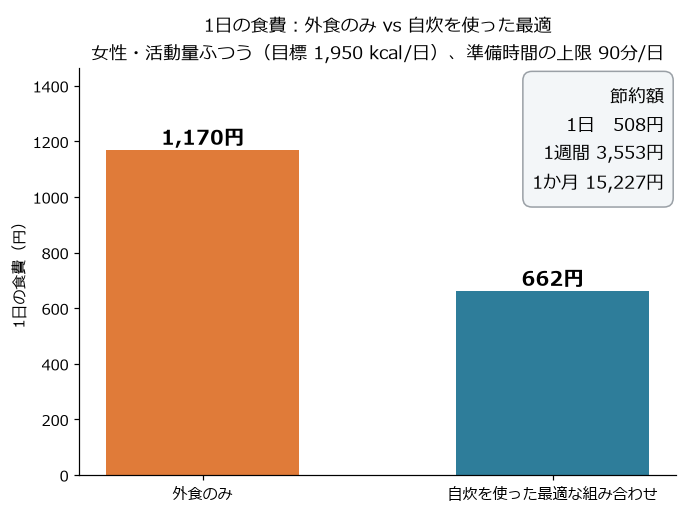

保存: ..\docs\fig\fig2_menu.png


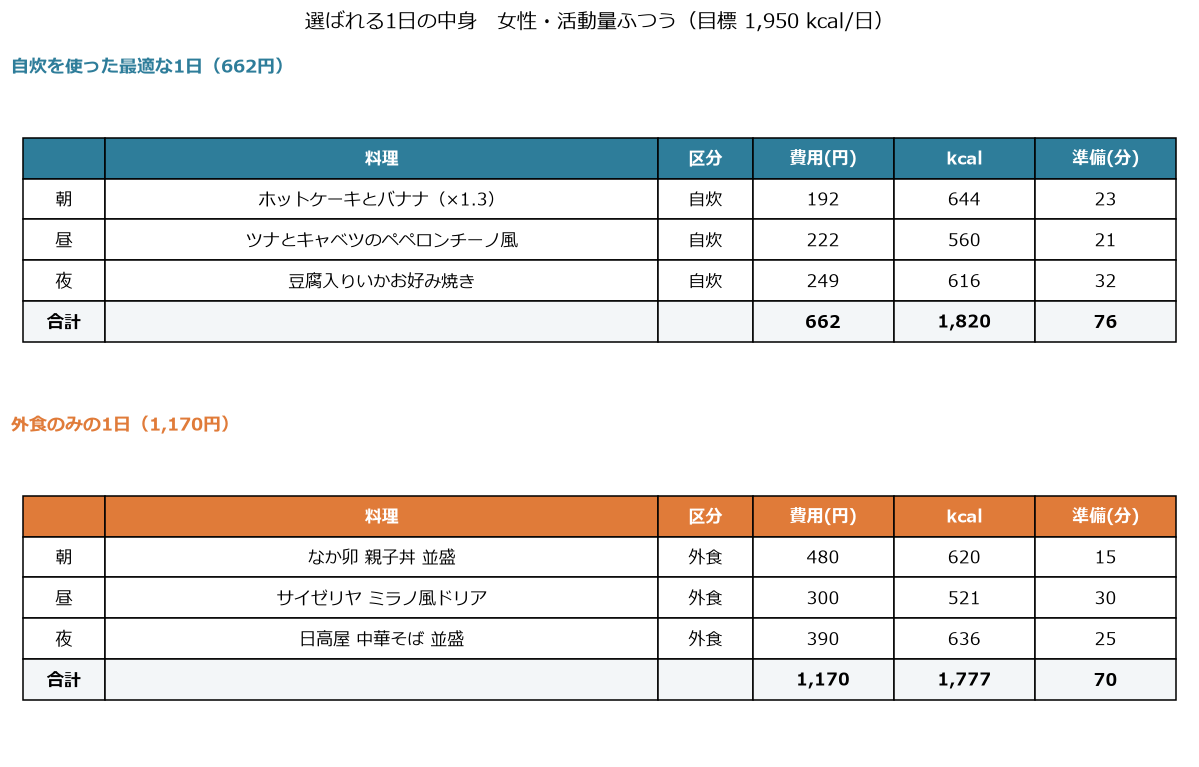

In [16]:
# ===== 発表用の図 ② 節約額と、選ばれる1日の中身 =====
# 最適な1日（自炊を使える）と、外食のみの1日を求める
P_BEST = optimize(P_SLOT, P_BUDGET, P_PREP, P_TARGET, config.AUX_NUTRIENTS)
P_EAT = eatout_baseline(P_SLOT, P_BUDGET, P_TARGET, config.AUX_NUTRIENTS)
# 両者の差（節約額）
P_SV = savings(P_BEST, P_EAT)
print(P_SV)

if P_SV["feasible"]:
    # --- 図1：1日のコストの比較 ---
    fig, ax = plt.subplots(figsize=(7, 4.8))
    costs = [P_SV["eatout_cost"], P_SV["best_cost"]]
    bars = ax.bar(["外食のみ", "自炊を使った最適な組み合わせ"], costs, color=[C_EAT, C_COOK], width=0.55)
    # 棒の上に金額を書く
    for b, v in zip(bars, costs):
        ax.text(b.get_x() + b.get_width() / 2, v + max(costs) * 0.015, f"{v:,.0f}円", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(costs) * 1.25)
    ax.set_ylabel("1日の食費（円）")
    # 節約額を右上に書く（1日・1週間・1か月）
    ax.text(0.98, 0.97, f"節約額\n1日   {P_SV['per_day']:,.0f}円\n1週間 {P_SV['per_week']:,.0f}円\n1か月 {P_SV['per_month']:,.0f}円",
            transform=ax.transAxes, ha="right", va="top", fontsize=12, linespacing=1.6,
            bbox=dict(boxstyle="round,pad=0.5", fc="#F3F6F8", ec=C_GRAY))
    ax.set_title(f"1日の食費：外食のみ vs 自炊を使った最適\n{P_LABEL}、準備時間の上限 {P_PREP}分/日", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    save_fig(fig, "fig1_savings.png")
    plt.show()

    # --- 図2：選ばれる1日の中身（2つの表を並べる） ---
    def day_table(ax, result, title, color):
        """選ばれた3食の表を ax に描く（枠・料理名・区分・費用・kcal・準備時間・合計）。"""
        sel = result["selected"].reset_index(drop=True)
        cell_text = [[SLOT_JA.get(r["slot"], r["slot"]), r["name"], r["type"], f"{r['cost_yen']:,.0f}",
                      f"{r['kcal']:,.0f}", f"{r['prep_min']:,.0f}"] for _, r in sel.iterrows()]
        # 合計の行
        cell_text.append(["合計", "", "", f"{sel['cost_yen'].sum():,.0f}", f"{sel['kcal'].sum():,.0f}", f"{sel['prep_min'].sum():,.0f}"])
        tb = ax.table(cellText=cell_text, colLabels=["", "料理", "区分", "費用(円)", "kcal", "準備(分)"],
                      colWidths=[0.07, 0.47, 0.08, 0.12, 0.12, 0.12], cellLoc="center", loc="center")
        tb.auto_set_font_size(False)
        tb.set_fontsize(11)
        tb.scale(1, 1.9)
        # ヘッダーに色をつけ、合計の行を太字にする
        for (r, c), cell in tb.get_celld().items():
            if r == 0:
                cell.set_facecolor(color)
                cell.set_text_props(color="white", fontweight="bold")
            elif r == len(cell_text):
                cell.set_text_props(fontweight="bold")
                cell.set_facecolor("#F3F6F8")
        ax.set_title(title, fontsize=12, loc="left", color=color, fontweight="bold")
        ax.axis("off")

    fig, axes = plt.subplots(2, 1, figsize=(11, 7))
    day_table(axes[0], P_BEST, f"自炊を使った最適な1日（{P_SV['best_cost']:,.0f}円）", C_COOK)
    day_table(axes[1], P_EAT, f"外食のみの1日（{P_SV['eatout_cost']:,.0f}円）", C_EAT)
    fig.suptitle(f"選ばれる1日の中身　{P_LABEL}", fontsize=13, y=0.99)
    fig.tight_layout()
    save_fig(fig, "fig2_menu.png")
    plt.show()
else:
    print("どちらかが解なしのため、図1・図2は描けない（予算 P_BUDGET を上げるか、利用者を変える）")

### 図3：利用者（性別 × 活動量）ごとの比較

                   label       best     eat  n_cooked
0   女性\n活動量低い\n1,700kcal   651.4445  1080.0         3
1  女性\n活動量ふつう\n1,950kcal   662.4445  1170.0         3
2   女性\n活動量高い\n2,250kcal   758.5555  1340.0         3
3   男性\n活動量低い\n2,250kcal   758.5555  1340.0         3
4  男性\n活動量ふつう\n2,600kcal   877.5555  1530.0         3
5   男性\n活動量高い\n3,000kcal  1697.7778     NaN         2
保存: ..\docs\fig\fig3_persona.png


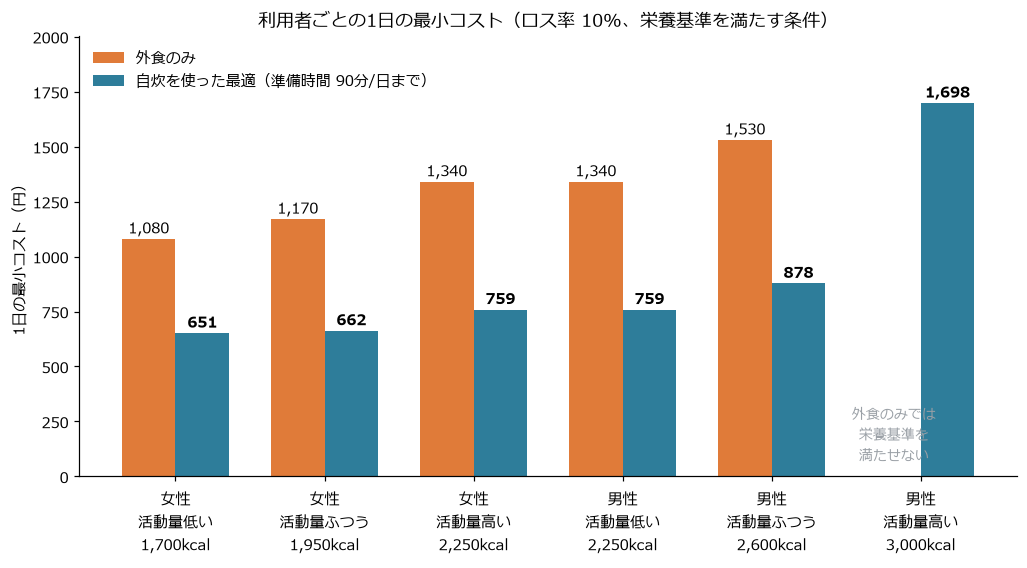

In [17]:
# ===== 発表用の図 ③ 利用者（性別 × 活動量）ごとの比較 =====
# 6通りの利用者それぞれで、最適な1日と外食のみの1日の最小コストを求める
rows = []
for sex in ("female", "male"):
    for act in ("low", "normal", "high"):
        k, tgt, slot = prepare(sex, act)
        b = optimize(slot, P_BUDGET, P_PREP, tgt)
        e = eatout_baseline(slot, P_BUDGET, tgt)
        rows.append({
            "label": f"{SEX_JA[sex]}\n活動量{ACT_JA[act]}\n{k:,}kcal",
            # 解なしは NaN にする
            "best": float(b["total_cost"]) if b["feasible"] else float("nan"),
            "eat": float(e["total_cost"]) if e["feasible"] else float("nan"),
            "n_cooked": int((b["selected"]["type"] == "自炊").sum()) if b["feasible"] else None,
        })
P_PERSONA = pd.DataFrame(rows)
print(P_PERSONA.to_string())

fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(P_PERSONA))
w = 0.36
ax.bar(x - w / 2, P_PERSONA["eat"], w, color=C_EAT, label="外食のみ")
ax.bar(x + w / 2, P_PERSONA["best"], w, color=C_COOK, label=f"自炊を使った最適（準備時間 {P_PREP}分/日まで）")
top = np.nanmax(P_PERSONA[["eat", "best"]].to_numpy())
for i, r in P_PERSONA.iterrows():
    # 外食のみが解なし（栄養基準を満たせない）の利用者には、その旨を書く
    if np.isnan(r["eat"]):
        ax.text(i - w / 2, top * 0.03, "外食のみでは\n栄養基準を\n満たせない", ha="center", va="bottom", fontsize=9, color=C_GRAY)
    else:
        ax.text(i - w / 2, r["eat"] + top * 0.015, f"{r['eat']:,.0f}", ha="center", fontsize=10)
    if not np.isnan(r["best"]):
        ax.text(i + w / 2, r["best"] + top * 0.015, f"{r['best']:,.0f}", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(P_PERSONA["label"])
ax.set_ylim(0, top * 1.18)
ax.set_ylabel("1日の最小コスト（円）")
ax.set_title(f"利用者ごとの1日の最小コスト（ロス率 {P_LOSS:.0%}、栄養基準を満たす条件）", fontsize=12)
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig(fig, "fig3_persona.png")
plt.show()

### 図4・図5：準備時間の上限、ロス率 × 準備時間

{'first_feasible_prep': 45, 'crossover_prep': 45, 'switch_preps': [60, 75, 90]}
保存: ..\docs\fig\fig4_breakeven.png


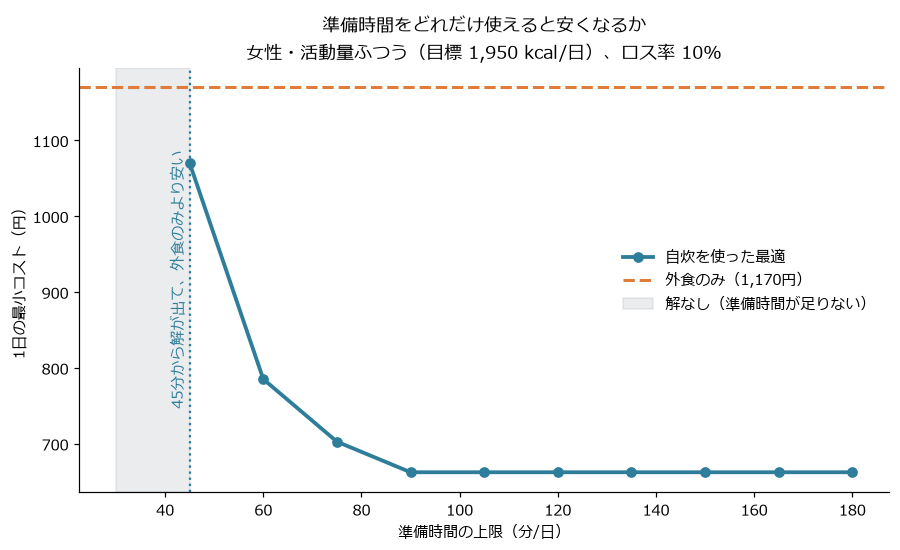

保存: ..\docs\fig\fig5_heatmap.png


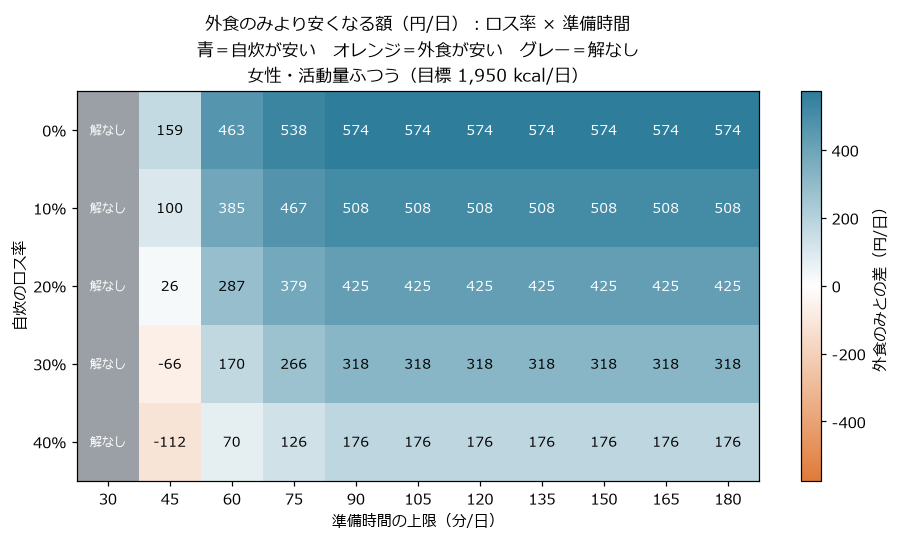

In [18]:
# ===== 発表用の図 ④ 準備時間の上限と、ロス率 × 準備時間 =====
# --- 図4：準備時間の上限を動かしたときの1日の最小コスト（損益分岐） ---
P_CURVE = breakeven_curve(P_SLOT, P_BUDGET, config.PREP_GRID, P_TARGET)
P_SW = switch_points(P_CURVE)
print(P_SW)

fig, ax = plt.subplots(figsize=(9.5, 5))
# 自炊を使った最適（解なしの上限は線が途切れる）
ax.plot(P_CURVE["max_prep_min"], P_CURVE["total_cost"], "o-", color=C_COOK, lw=2.5, label="自炊を使った最適")
# 外食のみ（準備時間によらず一定）
eat_cost = P_CURVE["eatout_cost"].iloc[0]
if not np.isnan(eat_cost):
    ax.axhline(eat_cost, color=C_EAT, ls="--", lw=2, label=f"外食のみ（{eat_cost:,.0f}円）")
# 解が出ない（栄養基準を満たせない）準備時間の範囲をグレーで塗る
first = P_SW["first_feasible_prep"]
if first is not None and first > P_CURVE["max_prep_min"].min():
    ax.axvspan(P_CURVE["max_prep_min"].min(), first, color=C_GRAY, alpha=0.2, label="解なし（準備時間が足りない）")
# 外食のみより安くなり始める上限（縦の点線。注記はグレーの帯の中に縦書きで置く）
if P_SW["crossover_prep"] is not None:
    ax.axvline(P_SW["crossover_prep"], color=C_COOK, ls=":", lw=1.5)
    ax.text(P_SW["crossover_prep"] - 1, 0.5, f"{P_SW['crossover_prep']}分から解が出て、外食のみより安い",
            transform=ax.get_xaxis_transform(), rotation=90, ha="right", va="center", fontsize=10, color=C_COOK)
ax.set_xlabel("準備時間の上限（分/日）")
ax.set_ylabel("1日の最小コスト（円）")
ax.set_title(f"準備時間をどれだけ使えると安くなるか\n{P_LABEL}、ロス率 {P_LOSS:.0%}", fontsize=12)
ax.legend(loc="center right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig(fig, "fig4_breakeven.png")
plt.show()

# --- 図5：ロス率 × 準備時間の上限（外食のみとの差・円/日） ---
P_GRID = loss_prep_grid(P_SLOT, P_BUDGET, config.PREP_GRID, config.LOSS_GRID, P_TARGET)
pv = P_GRID.pivot(index="loss_rate", columns="max_prep_min", values="saving_per_day")
fig, ax = plt.subplots(figsize=(10, 4.6))
# 色：自炊が安い（プラス）＝青、外食が安い（マイナス）＝オレンジ、0＝白、解なし＝グレー
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("eat_cook", [C_EAT, "white", C_COOK]).copy()
cmap.set_bad(C_GRAY)
vals = pv.to_numpy(float)
vlim = np.nanmax(np.abs(vals))
im = ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, norm=TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim), aspect="auto")
ax.set_xticks(range(len(pv.columns)))
ax.set_xticklabels([f"{c:g}" for c in pv.columns])
ax.set_yticks(range(len(pv.index)))
ax.set_yticklabels([f"{r:.0%}" for r in pv.index])
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.iloc[i, j]
        if np.isnan(v):
            ax.text(j, i, "解なし", ha="center", va="center", fontsize=8, color="white")
        else:
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > vlim * 0.6 else "black")
ax.set_xlabel("準備時間の上限（分/日）")
ax.set_ylabel("自炊のロス率")
ax.set_title(f"外食のみより安くなる額（円/日）：ロス率 × 準備時間\n青＝自炊が安い　オレンジ＝外食が安い　グレー＝解なし\n{P_LABEL}", fontsize=11)
fig.colorbar(im, ax=ax, label="外食のみとの差（円/日）")
save_fig(fig, "fig5_heatmap.png")
plt.show()

### 図6：どの仮定が結果を一番動かすか（トルネード図）

       parameter  value  feasible   total_cost   base_cost  change_yen  saving_per_day  n_cooked
0   max_prep_min   30.0     False          NaN  662.444444         NaN             NaN       NaN
1   max_prep_min   45.0      True  1070.000000  662.444444  407.555556      100.000000       2.0
2   max_prep_min   60.0      True   785.222222  662.444444  122.777778      384.777778       3.0
3   max_prep_min   75.0      True   702.777778  662.444444   40.333333      467.222222       3.0
4   max_prep_min   90.0      True   662.444444  662.444444    0.000000      507.555556       3.0
5   max_prep_min  105.0      True   662.444444  662.444444    0.000000      507.555556       3.0
6   max_prep_min  120.0      True   662.444444  662.444444    0.000000      507.555556       3.0
7   max_prep_min  135.0      True   662.444444  662.444444    0.000000      507.555556       3.0
8   max_prep_min  150.0      True   662.444444  662.444444    0.000000      507.555556       3.0
9   max_prep_min  165.0      T

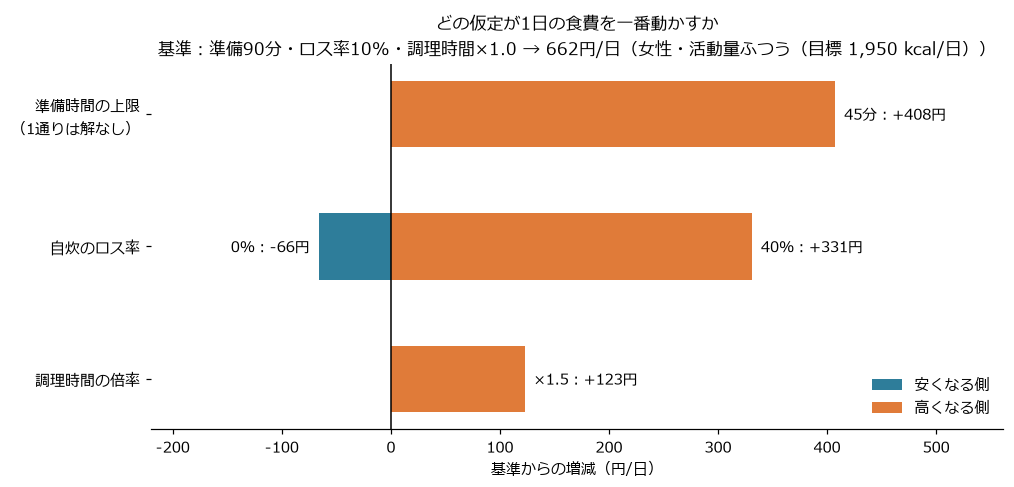

In [19]:
# ===== 発表用の図 ⑤ どの仮定が結果を一番動かすか（トルネード図） =====
# 基準の条件：準備時間 P_PREP 分、ロス率 P_LOSS、調理時間の倍率 1.0
base_p = {"max_prep_min": P_PREP, "loss_rate": P_LOSS, "cook_factor": 1.0}
# 動かす値（config.py）
grids_p = {"max_prep_min": config.PREP_GRID, "loss_rate": config.LOSS_GRID, "cook_factor": config.COOK_FACTOR_GRID}
# 1つずつ動かして最適化を繰り返す
P_OAT = oat_sensitivity(P_SLOT, P_BUDGET, P_TARGET, base_p, grids_p)
print(P_OAT.drop(columns="meal_ids").to_string())

# 図に使う日本語名と、値の書き方
PARAM_JA = {"max_prep_min": "準備時間の上限", "loss_rate": "自炊のロス率", "cook_factor": "調理時間の倍率"}
PARAM_FMT = {"max_prep_min": lambda v: f"{v:g}分", "loss_rate": lambda v: f"{v:.0%}", "cook_factor": lambda v: f"×{v:g}"}

# 条件ごとに、基準からの増減の最小・最大を取り出す（解なしの値は除く）
bars = []
for p in grids_p:
    sub = P_OAT[(P_OAT["parameter"] == p) & P_OAT["feasible"]]
    if sub.empty:
        continue
    lo, hi = sub.loc[sub["change_yen"].idxmin()], sub.loc[sub["change_yen"].idxmax()]
    n_ng = int(((P_OAT["parameter"] == p) & ~P_OAT["feasible"]).sum())
    bars.append({"name": PARAM_JA[p], "lo": lo["change_yen"], "hi": hi["change_yen"],
                 "lo_v": PARAM_FMT[p](lo["value"]), "hi_v": PARAM_FMT[p](hi["value"]), "span": hi["change_yen"] - lo["change_yen"], "n_ng": n_ng})
# 幅の大きい順（上が最も影響が大きい）
bars.sort(key=lambda b: -b["span"])

fig, ax = plt.subplots(figsize=(10, 4.3))
ypos = np.arange(len(bars))
ax.barh(ypos, [b["lo"] for b in bars], color=C_COOK, height=0.5, label="安くなる側")
ax.barh(ypos, [b["hi"] for b in bars], color=C_EAT, height=0.5, label="高くなる側")
off = max(b["span"] for b in bars) * 0.02
for y, b in zip(ypos, bars):
    if b["lo"] < -0.5:
        ax.text(b["lo"] - off, y, f"{b['lo_v']}：{b['lo']:+,.0f}円", ha="right", va="center", fontsize=10)
    if b["hi"] > 0.5:
        ax.text(b["hi"] + off, y, f"{b['hi_v']}：{b['hi']:+,.0f}円", ha="left", va="center", fontsize=10)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels([b["name"] + (f"\n（{b['n_ng']}通りは解なし）" if b["n_ng"] else "") for b in bars])
ax.invert_yaxis()
base_cost = P_OAT["base_cost"].iloc[0]
ax.set_xlabel("基準からの増減（円/日）")
ax.set_title(f"どの仮定が1日の食費を一番動かすか\n基準：準備{P_PREP}分・ロス率{P_LOSS:.0%}・調理時間×1.0 → {base_cost:,.0f}円/日（{P_LABEL}）", fontsize=11)
# 左右の余白（ラベルが切れないように）
xmin, xmax = ax.get_xlim()
pad = (xmax - xmin) * 0.25
ax.set_xlim(xmin - pad, xmax + pad)
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
save_fig(fig, "fig6_tornado.png")
plt.show()

### 図7：栄養基準を満たすための追加費用

栄養あり 662.4445000000001円 / 栄養なし 618.2223円 / 差 44.22220000000004円
保存: ..\docs\fig\fig7_nutrition_gap.png


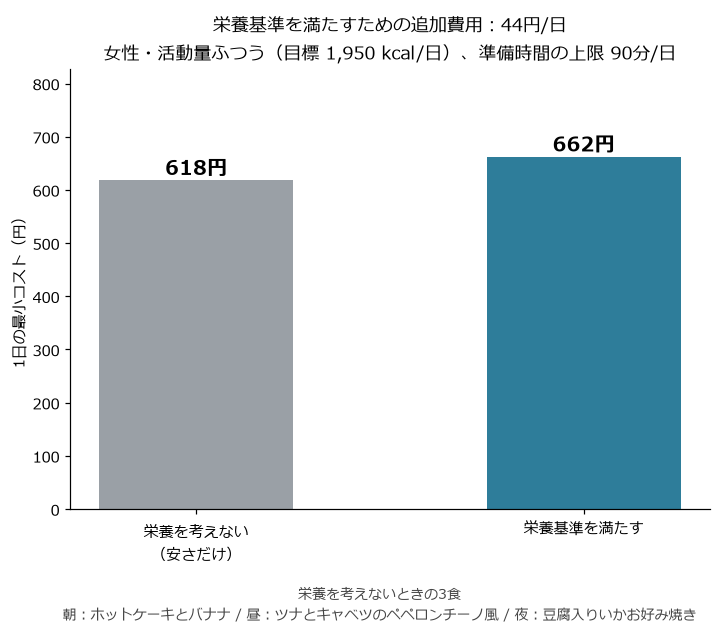

In [20]:
# ===== 発表用の図 ⑥ 栄養基準を満たすための追加費用 =====
# 栄養制約あり／なしの最小コストを比べる
P_GAP = nutrition_cost_gap(P_SLOT, P_BUDGET, P_PREP, P_TARGET)
print(f"栄養あり {P_GAP['cost_with']}円 / 栄養なし {P_GAP['cost_without']}円 / 差 {P_GAP['gap_yen']}円")

if P_GAP["gap_yen"] is not None:
    fig, ax = plt.subplots(figsize=(7.5, 5.2))
    vals = [P_GAP["cost_without"], P_GAP["cost_with"]]
    bs = ax.bar(["栄養を考えない\n（安さだけ）", "栄養基準を満たす"], vals, color=[C_GRAY, C_COOK], width=0.5)
    for b, v in zip(bs, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + max(vals) * 0.015, f"{v:,.0f}円", ha="center", fontsize=13, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel("1日の最小コスト（円）")
    ax.set_title(f"栄養基準を満たすための追加費用：{P_GAP['gap_yen']:,.0f}円/日\n{P_LABEL}、準備時間の上限 {P_PREP}分/日", fontsize=12)
    # 栄養を考えないときに選ばれる3食を下に書く
    sel = P_GAP["without_nutrition"]["selected"]
    names = " / ".join(f"{SLOT_JA.get(r['slot'], r['slot'])}：{r['name']}" for _, r in sel.iterrows())
    fig.text(0.5, -0.02, "栄養を考えないときの3食\n" + names, ha="center", va="top", fontsize=9, color="#444444", wrap=True)
    ax.spines[["top", "right"]].set_visible(False)
    save_fig(fig, "fig7_nutrition_gap.png")
    plt.show()
else:
    print("どちらかが解なしのため、図7は描けない")

## 検算

1. `apply_loss(meals, 0.1)` が、`meals.csv` の `cost_yen`（ロス率10%で作られている）と一致するか
2. 損益分岐の各点が、愚直な三重ループ（`optimize.ipynb` の検算と同じ考え方）の最小コストと一致するか
3. 外食のみの基準が、外食だけの表での愚直な探索と一致するか

In [21]:
# 組み合わせ（直積）を作る標準ライブラリ
import itertools


def naive_min_cost(df, budget, max_prep, target):
    """愚直な三重ループ。optimize の最小コストと一致するかの検算用。"""
    # 行番号を0から振り直す
    df = df.reset_index(drop=True)
    # 枠ごとの候補の行番号（optimize と同じ条件）
    cand = {s: [i for i in range(len(df)) if df.loc[i, f"can_{s}"]] for s in SLOTS}
    # 「同じ食事」の判定キー（optimize と同じ。recipe_id があればそれ、なければ行番号）
    grp = df["recipe_id"].to_numpy() if "recipe_id" in df.columns else list(range(len(df)))
    # 列をリストにしておく（実データは候補が多く、組が数十万通りになるため、表から毎回引くと遅すぎる）
    cost, prep = df["cost_yen"].tolist(), df["prep_min"].tolist()
    nut = {key: df[key].tolist() for key in target}
    # 見つかった最小コスト
    best = None
    # 朝×昼×夜のすべての組を1つずつ調べる（遅いが単純）
    for i, j, k in itertools.product(cand["morning"], cand["lunch"], cand["dinner"]):
        # 同じ食事（同じ recipe_id）が重複していたら除外
        if len({grp[i], grp[j], grp[k]}) < 3:
            continue
        # 3食の合計コスト・準備時間
        total = cost[i] + cost[j] + cost[k]
        # 予算・準備時間を超えたら除外
        if total > budget or prep[i] + prep[j] + prep[k] > max_prep:
            continue
        # 栄養が全項目で範囲内か調べる
        ok = True
        for key, (lo, hi) in target.items():
            t = nut[key][i] + nut[key][j] + nut[key][k]
            ok &= (lo is None or t >= lo) and (hi is None or t <= hi)
        # 条件を満たし、これまでより安ければ更新
        if ok and (best is None or total < best):
            best = total
    return best


# 1. ロス率10%の再計算が CSV の cost_yen と一致する（浮動小数の誤差は許す）
assert np.allclose(apply_loss(meals, 0.1)["cost_yen"], meals["cost_yen"]), "apply_loss(0.1) が CSV と合わない"
# ロス率0なら自炊も食材費そのまま
assert np.allclose(apply_loss(meals, 0.0)["cost_yen"], meals["base_cost_yen"])

# 2. 損益分岐の各点が愚直な探索と一致する
for row in curve.itertuples():
    # 愚直な探索の答え（解なしは None）
    expected = naive_min_cost(meals_slot, BUDGET, row.max_prep_min, target)
    # optimize の答え（解なしは None）
    got = None if not row.feasible else row.total_cost
    # どちらも解なし、または同じコストなら OK。違えば停止
    assert (got is None and expected is None) or got == expected, (row.max_prep_min, got, expected)

# 3. 外食のみの基準が一致する
eat_only = meals_slot[meals_slot["type"] == EATOUT]  # 外食の行だけ
expected = naive_min_cost(eat_only, BUDGET, float("inf"), target)  # 準備時間は制約なし
got = baseline["total_cost"] if baseline["feasible"] else None
assert (got is None and expected is None) or got == expected, (got, expected)

# 4. ヒートマップのロス率10%の行が、損益分岐（元の表＝10%）と一致する
row10 = grid[np.isclose(grid["loss_rate"], 0.1)].set_index("max_prep_min")["total_cost"]
assert np.allclose(row10.to_numpy(float), curve.set_index("max_prep_min")["total_cost"].to_numpy(float),
                   equal_nan=True)

# 5. 栄養制約なしの最小コストが、愚直な探索（栄養の条件なし）と一致し、栄養ありより安いか同額
expected = naive_min_cost(meals_slot, BUDGET, 90, {})  # 栄養制約なしの愚直な探索
assert gap["cost_without"] == expected, (gap["cost_without"], expected)
assert gap["gap_yen"] >= -1e-9, gap["gap_yen"]  # 栄養を外して高くなることはない

# 6. OAT：基準条件の行が基準のコストと一致し、条件を動かすと単調に変わる
for name in base:
    # 動かした値が基準と同じ行は、基準のコストと同じになる
    same = oat[(oat["parameter"] == name) & (oat["value"] == base[name])]
    assert len(same) == 1 and np.isclose(same["total_cost"].iloc[0], same["base_cost"].iloc[0]), name
# 準備時間の上限を長くするとコストは下がるか同じ（-1）。ロス率・調理時間を増やすと上がるか同じ（+1）
for name, sign in [("max_prep_min", -1), ("loss_rate", +1), ("cook_factor", +1)]:
    c = oat[(oat["parameter"] == name) & oat["feasible"]].sort_values("value")["total_cost"].to_numpy(float)
    assert (sign * np.diff(c) >= -1e-6).all(), (name, c)

# 7. build_nutrition_target を手計算と照合する（2000 kcal。比率は引数で明示）
t = build_nutrition_target(2000, {"protein_g": (0.13, 0.20), "fat_g": (0.20, 0.30), "carb_g": (0.50, 0.65)},
                           {"protein_g": 4, "fat_g": 9, "carb_g": 4}, 0.10)
assert np.allclose(t["kcal"], (1800, 2200))
assert np.allclose(t["protein_g"], (65, 100))                  # 2000×0.13÷4, 2000×0.20÷4
assert np.allclose(t["fat_g"], (2000 * 0.20 / 9, 2000 * 0.30 / 9))  # 44.4〜66.7 g
assert np.allclose(t["carb_g"], (250, 325))

# 8. nutrition_adequacy の判定（不足・超過・基準未設定・データなし）
a = nutrition_adequacy({"kcal": 2000, "fiber_g": 10, "salt_g": 8.0},
                       {"kcal": (1800, 2200)},
                       {"fiber_g": ("min", 20), "salt_g": ("max", 7), "iron_mg": None})
assert list(a["status"]) == ["充足", "不足", "超過", "データなし"], list(a["status"])
assert np.isclose(a.loc[a["nutrient"] == "fiber_g", "ratio_pct"].iloc[0], 50.0)  # 10 ÷ 20 × 100
b = nutrition_adequacy({"iron_mg": 6.0}, {}, {"iron_mg": None})
assert list(b["status"]) == ["基準未設定"], list(b["status"])

print("検算 OK")

検算 OK
